# Проект. Исследование стартапов

## Введение

Поле для вашего введения: опишите контекст и цели проекта. Чтобы изменить содержимое ячейки, дважды нажмите на неё или нажмите «Ввод».

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации

In [230]:
!pip install phik -q
#!pip install tzdata

In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix


sns.set_theme(style="ticks")

In [232]:
readInv = pd.read_csv('data/cb_investments.csv', sep=';', low_memory=False)
display(readInv)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [233]:
readRet = pd.read_csv('data/cb_returns.csv')
display(readRet)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.7000,55.4000,0.0000,78.2100,0.0000,8.6600,6.4300,0.0000,0.0000,0.9400,0.0000,0.2000,0.0000
1,2001,2.8800,23.4900,0.0000,21.5000,0.0100,4.4900,1.1800,0.0000,0.0000,0.4600,0.0000,0.4600,0.0000
2,2002,6.5900,209.4200,0.0000,25.7700,0.0200,3.4200,3.4100,0.0000,1.5100,0.3400,0.0000,0.0600,0.0000
3,2003,7.7400,233.8600,0.0000,9.4000,0.0100,1.0900,3.4100,0.0000,1.6200,2.1100,0.0000,0.0800,0.0000
4,2004,9.9300,555.9000,0.0000,33.1900,0.0100,13.5500,9.1800,0.0000,2.1900,3.3800,0.0000,0.5500,0.0000
5,2005,26.6000,2628.9200,0.0000,9.5100,0.0200,35.0900,31.0600,0.0000,2.4000,3.5100,0.0000,0.0500,0.0000
6,2006,61.8100,3100.1800,0.1900,46.7400,1.7800,113.2100,47.7500,0.0000,16.6700,20.5800,0.0000,0.1200,0.0000
7,2007,70.4100,3585.3700,0.0100,55.3700,3.2200,125.6800,164.5100,0.0000,88.8100,24.3600,0.0000,0.5700,0.0000
8,2008,89.7200,2717.0200,0.0300,41.0200,1.7100,397.5400,102.8300,0.0000,130.3800,84.2800,0.0000,0.4700,0.0000
9,2009,160.2100,2501.2900,0.1800,37.5000,2.2500,394.1000,97.2100,0.0000,203.7000,76.7600,0.0000,0.1200,0.0200


Выведите информацию, которая необходима для принятия решений о предобработке.

In [234]:
print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [235]:
print(readRet.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB
None


In [236]:
print(readInv.isna().sum())

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [237]:
round(readInv.isna().mean().sort_values(ascending=False),2)

state_code             0.4400
mid_funding_at         0.4400
participants           0.4400
founded_month          0.2900
founded_quarter        0.2900
founded_at             0.2900
founded_year           0.2900
city                   0.2000
country_code           0.1900
region                 0.1900
category_list          0.1600
 market                0.1600
homepage_url           0.1500
status                 0.1100
name                   0.0900
private_equity         0.0900
round_E                0.0900
round_F                0.0900
round_D                0.0900
round_C                0.0900
round_G                0.0900
round_B                0.0900
round_A                0.0900
product_crowdfunding   0.0900
secondary_market       0.0900
post_ipo_debt          0.0900
post_ipo_equity        0.0900
venture                0.0900
grant                  0.0900
angel                  0.0900
debt_financing         0.0900
convertible_note       0.0900
undisclosed            0.0900
equity_cro

### Первичное знакомство с данными

#### Файл `cd_investments.csv`

При первом просмотре данных были замечены **выбросы, присутствующие во множестве столбцов**. Также обратило на себя внимание то, что **в конце таблицы данные содержат `null`-значения** — вероятно, большинство пропусков в датасете связано именно с этими строками.

Наибольшее количество пропусков (около **44%**) сосредоточено в столбцах **`state_code`**, **`mid_funding_at`** и **`participants`**.

Можно предположить, что данные содержат **4 856 полностью пустых строк**, которые в дальнейшем потребуется обработать (например, удалить).

Также заметно, что в наименованиях столбцов присутствуют **излишние пробелы**, которые в дальнейшем будет необходимо обработать.

#### Файл `cb_returns.csv`

В данных **отсутствуют пропуски**, а наименования столбцов не требуют исправлений. При этом можно **уменьшить типы значений** (понизить размерность числовых столбцов) для оптимизации памяти.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [238]:
#Убираем излишние пробелы в названиях столбцов

col  = list(readInv.columns)
for i in range(len(col)):
    if col[i].find(' ') == 0:
        col[i] = col[i].replace(' ','')
readInv.columns = col

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [239]:
readInv['funding_total_usd'] = readInv['funding_total_usd'].str.replace(',','')
readInv['funding_total_usd'] = pd.to_numeric(readInv['funding_total_usd'],errors='coerce')

print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3   market                45477 non-null  object 
 4   funding_total_usd     40907 non-null  float64
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [240]:
readInv['founded_at'] = pd.to_datetime(readInv['founded_at'], errors='coerce').dt.to_pydatetime()
readInv['founded_month'] = pd.to_datetime(readInv['founded_month'], errors='coerce').dt.to_pydatetime()

readInv['first_funding_at'] = pd.to_datetime(readInv['first_funding_at'], errors='coerce').dt.to_pydatetime()
readInv['mid_funding_at'] = pd.to_datetime(readInv['mid_funding_at'], errors='coerce').dt.to_pydatetime()
readInv['last_funding_at'] = pd.to_datetime(readInv['last_funding_at'], errors='coerce').dt.to_pydatetime()


#readInv['founded_at'] = readInv['founded_at'].astype('datetime64[D]')
#readInv['founded_month'] = readInv['founded_month'].astype('datetime64[D]')
readInv['founded_year'] = pd.to_numeric(readInv['founded_year'])

#readInv['first_funding_at'] = readInv['first_funding_at'].astype('datetime64[D]')
#readInv['mid_funding_at'] = readInv['mid_funding_at'].astype('datetime64[D]')
#readInv['last_funding_at'] = readInv['last_funding_at'].astype('datetime64[D]')

C:\Users\Александр\AppData\Local\Temp\ipykernel_4748\646570742.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  readInv['founded_at'] = pd.to_datetime(readInv['founded_at'], errors='coerce').dt.to_pydatetime()
C:\Users\Александр\AppData\Local\Temp\ipykernel_4748\646570742.py:1: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  readInv['founded_at'] = pd.to_datetime(readInv['founded_at'], errors='coerce').dt.to_pydatetime()
C:\Users\Александр\AppData\Local\Temp\ipykernel_4748\646570742.py:2: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead 

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [241]:
readRet = readRet.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [242]:
print(f'Было удаленно {readInv.isna().all(axis=1).sum()} строк, которые являлись полностью пустыми')
readInv = readInv.dropna(how = 'all')

readInv.isna().sum()

Было удаленно 4856 строк, которые являлись полностью пустыми


name                        1
homepage_url             3449
category_list            3961
market                   3961
funding_total_usd        8531
status                   1314
country_code             5273
state_code              19277
region                   5273
city                     6116
funding_rounds              0
participants            18965
founded_at              10885
founded_month           10956
founded_quarter         10956
founded_year            10884
first_funding_at           10
mid_funding_at          19150
last_funding_at             6
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A                     0
round_B   

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [243]:
##Удаление данных в которых пропушенна информация про финансирование

print(readInv.duplicated().sum())
readInv['funding_total_usd'].dropna()

0


0       90000000.0000
1        2000000.0000
2        9000000.0000
3        7700000.0000
4         540000.0000
             ...     
49433    1500000.0000
49434    9000000.0000
49435     250000.0000
49436   34000000.0000
49437      11500.0000
Name: funding_total_usd, Length: 40907, dtype: float64

In [244]:
##Заполненеи пропусков среднего дня

readInv['mid_funding_at'] = readInv['mid_funding_at'].fillna(
    readInv['first_funding_at'] 
    + (readInv['last_funding_at'] - readInv['first_funding_at']) / 2
)

In [245]:
readInv['founded_month'] = readInv['founded_at'].dt.strftime('%Y-%m')

readInv['founded_quarter'] = (
    readInv['founded_at']
    .dt.to_period('Q')
    .astype(str)
    .str.replace('Q', '-Q', regex=False)
    .where(readInv['founded_at'].notna())
)


In [246]:
readInv = readInv.reset_index()
readInv.info()
readInv.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49438 entries, 0 to 49437
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   index                 49438 non-null  int64         
 1   name                  49437 non-null  object        
 2   homepage_url          45989 non-null  object        
 3   category_list         45477 non-null  object        
 4   market                45477 non-null  object        
 5   funding_total_usd     40907 non-null  float64       
 6   status                48124 non-null  object        
 7   country_code          44165 non-null  object        
 8   state_code            30161 non-null  object        
 9   region                44165 non-null  object        
 10  city                  43322 non-null  object        
 11  funding_rounds        49438 non-null  float64       
 12  participants          30473 non-null  float64       
 13  founded_at      

index                       0
name                        1
homepage_url             3449
category_list            3961
market                   3961
funding_total_usd        8531
status                   1314
country_code             5273
state_code              19277
region                   5273
city                     6116
funding_rounds              0
participants            18965
founded_at              10885
founded_month           10885
founded_quarter         10885
founded_year            10884
first_funding_at           10
mid_funding_at              8
last_funding_at             6
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A   

### Результаты предобработки данных

В ходе преобразования данных были выполнены следующие действия:

**Файл `cd_investments.csv`:**
- Очищены названия столбцов от лишних пробелов;
- Столбцы `founded_at`, `founded_month`, `founded_year`, `first_funding_at`, `mid_funding_at`, `last_funding_at` приведены к формату даты;
- Удалены строки, в которых пропуски присутствовали во **всех** столбцах — их оказалось **4 856**;
- Удалены явные дубликаты;
- Удалены все пустые значения в столбце `funding_total_usd`;
- Восстановлены пропуски в средних значениях дат — найдено среднее значение между первой и последней датой финансирования;
- Восстановлены пропуски в столбцах `founded_month` и `founded_quarter` при помощи столбца `founded_at`.

**Файл `cd_returns.csv`:**
- Столбец `year` стал индексами.

**Обработка пропусков:** пока что было принято решение **не удалять и не заполнять оставшиеся пропуски**, так как пока не до конца понятно, какие именно данные будут использоваться в дальнейшем. Если с ними будут производиться какие-либо действия, это будет указано ниже.

**Итог по объёму данных:**
- До всех преобразований в данных было **54 293 строки**;
- После преобразований осталось **49 437 строк**, что составляет **91%** от исходного объёма данных.

---
<!-- Место для дополнений о добавлении текста позже -->

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [247]:
first = readInv['first_funding_at']
second = readInv['last_funding_at']

readInv['count_days'] = (second - first).dt.days

readInv.loc[readInv['count_days'] == 0, 'company_type'] = 'Единичное финансирование'
readInv.loc[((readInv['count_days'] > 0) & (readInv['count_days'] <= 365)), 'company_type'] = 'Срок финансирования до года'
readInv.loc[readInv['count_days'] > 365, 'company_type'] = 'Срок финансирования более года'

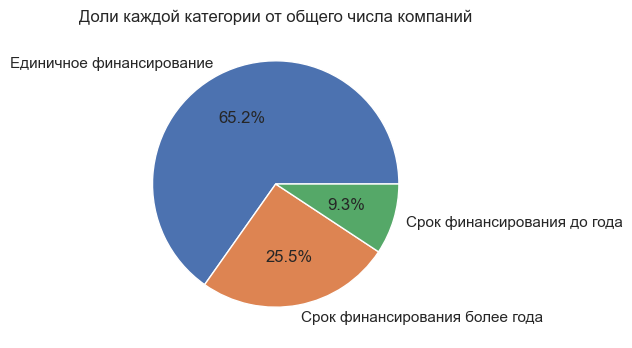

In [248]:
data = readInv['company_type'].value_counts(normalize=True)

plt.figure(figsize=(4,4))

data.plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Доли каждой категории от общего числа компаний'
)

plt.ylabel('')
plt.show()

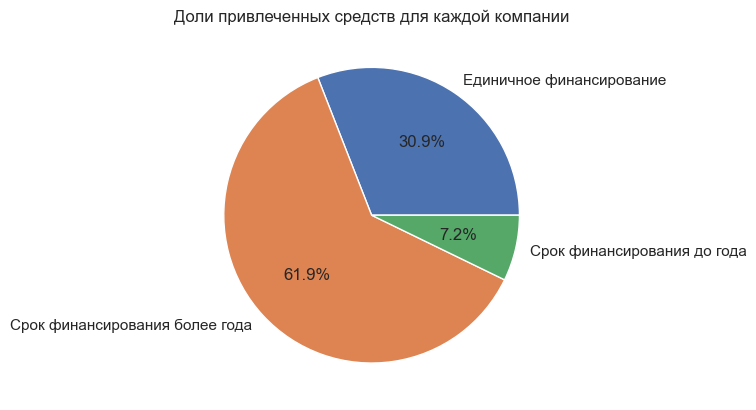

In [249]:
data = readInv.groupby('company_type')['funding_total_usd'].sum()
data = data/data.sum()*100

data.plot(
    kind='pie',
    title = 'Доли привлеченных средств для каждой компании',
    autopct='%1.1f%%',
)

plt.ylabel('')
plt.show()

### Вывод по распределению финансирования

По графикам видно, что:

- **Наибольшую долю по количеству** занимает группа **«Единичное финансирование»** — **62,5%**, а наименьшую — группа **«Срок финансирования до года»** — **9,3%**.
- **Наибольшая доля по привлечённым средствам** приходится на группу **«Срок финансирования более года»** — **61,9%**, а самая маленькая — также у группы **«Срок финансирования до года»** — **7,2%**.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [250]:
df = readInv.copy()

market_counts = df['market'].value_counts()

market_category = pd.cut(
    market_counts,
    bins=[0, 35, 121, float('inf')],
    labels=['нишевый', 'средний', 'массовый'],
    right=False
)

df['market_category'] = df['market'].map(market_category.astype(str))
df['market'] = df['market'].str.replace(' ','')

df['market_category'].value_counts()

market_category
массовый    36883
средний      5640
нишевый      2954
Name: count, dtype: int64

Text(0, 0.5, 'Кол-во комапаний в категории')

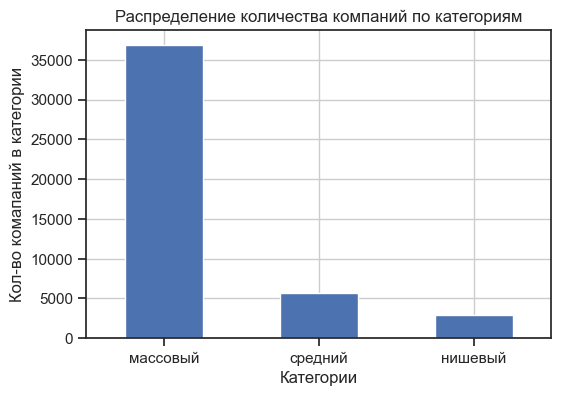

In [251]:
plt.figure(figsize=(6,4))

df['market_category'].value_counts().plot(
    kind = 'bar',
    title = 'Распределение количества компаний по категориям',
    rot =  0)

plt.grid()
plt.xlabel('Категории')
plt.ylabel('Кол-во комапаний в категории')

In [252]:
data = df['market_category'].value_counts()
data = data/data.sum()

data

market_category
массовый   0.8110
средний    0.1240
нишевый    0.0650
Name: count, dtype: float64

In [253]:
df.loc[df['market_category'] == 'средний', 'market'] = 'mid'
df.loc[df['market_category'] == 'нишевый', 'market'] = 'niche'

df['market'] = df['market'].str.replace(' ','')

In [254]:
df['market'].value_counts()

market
mid                   5640
Software              5353
Biotechnology         3699
niche                 2954
Mobile                2513
E-Commerce            2035
CuratedWeb            1866
EnterpriseSoftware    1339
CleanTechnology       1230
HealthCare            1224
Games                 1216
Advertising           1109
Hardware+Software     1096
HealthandWellness      934
SocialMedia            930
Education              894
Finance                890
Manufacturing          750
Analytics              649
Security               543
Semiconductors         509
Consulting             493
Hospitality            470
WebHosting             452
Fashion                402
RealEstate             398
News                   385
Travel                 367
Messaging              307
Music                  303
Search                 299
SaaS                   277
Medical                261
Sports                 260
Technology             259
Apps                   255
Internet             

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


### Вывод по распределению по сегментам рынка

По графику видно, что **наибольший объём имеет сегмент «массовый»**, а **наименьший объём — у сегмента «нишевый»**.

**Дополнительно:** столбец `market` был изменён — все наименования в категориях «средний» и «нишевый» заменены на заглушки **`mid`** и **`niche`** соответственно.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

In [255]:
pd.options.display.float_format = '{:.0f}'.format

df['funding_total_usd'].describe()

count         40907
mean       15912526
std       168678800
min               1
25%          350000
50%         2000000
75%        10000000
max     30079503000
Name: funding_total_usd, dtype: float64

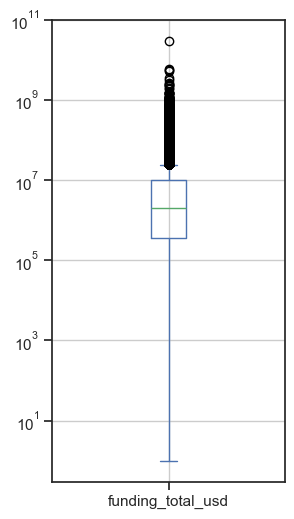

In [256]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3,6))
plt.yscale('log') # Ключевое изменение
df['funding_total_usd'].plot(kind='box')
plt.grid()
plt.show()

### Вывод по распределению объёма финансирования

По графику («ящик с усами») видно, что **медиана находится чуть выше отметки \(10^6\)** — типичное значение финансирования составляет примерно **1,2–1,5 млн долларов**.

- Нижняя и верхняя границы «ящика» находятся в диапазоне от **~500 тыс.** до **~10 млн долларов** — соответственно, **50% компаний** получили финансирование именно в этом диапазоне;
- **Выбросами** являются значения выше **10 млрд долларов**, а самый большой выброс — **30 млрд долларов**.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [257]:
data = df.groupby('market_category')['funding_total_usd'].describe()

bounds = {}
for grp, subdf in df.groupby('market'):
    q1 = subdf['funding_total_usd'].quantile(0.25)
    q3 = subdf['funding_total_usd'].quantile(0.75)
    iqr = q3 - q1
    bounds[grp] = {
        'lower': q1 - 1.5 * iqr,
        'upper': q3 + 1.5 * iqr
    }
    print(f"Группа {grp}: нижняя граница = {bounds[grp]['lower']:.0f}, верхняя = {bounds[grp]['upper']:.0f}")

data

Группа Advertising: нижняя граница = -16564684, верхняя = 29138811
Группа Analytics: нижняя граница = -16300000, верхняя = 28500000
Группа Apps: нижняя граница = -3030440, верхняя = 5313924
Группа Automotive: нижняя граница = -14327778, верхняя = 24596667
Группа BigData: нижняя граница = -9750000, верхняя = 17050000
Группа Biotechnology: нижняя граница = -29213031, верхняя = 52688385
Группа CleanTechnology: нижняя граница = -38085956, верхняя = 67476592
Группа CloudComputing: нижняя граница = -13500000, верхняя = 24100000
Группа Consulting: нижняя граница = -9025625, верхняя = 15423375
Группа CuratedWeb: нижняя граница = -6555625, верхняя = 11459375
Группа Design: нижняя граница = -6650215, верхняя = 11497025
Группа E-Commerce: нижняя граница = -9875000, верхняя = 17125000
Группа Education: нижняя граница = -7506042, верхняя = 13043404
Группа EnterpriseSoftware: нижняя граница = -19456250, верхняя = 35093750
Группа Entertainment: нижняя граница = -9950000, верхняя = 16850000
Группа Fas

,count,mean,std,min,25%,50%,75%,max
market_category,,,,,,,,
массовый,31253,16392388,185272420,1,475000,2369248,10488435,30079503000
нишевый,2376,19397939,106318504,100,250000,1300000,8000000,3500000000
средний,4775,14025597,70396738,890,250000,1403970,7966176,2351140000


In [258]:
def is_anomaly(row):
    grp = row['market']
    val = row['funding_total_usd']
    if pd.isna(grp) or grp not in bounds:
        return False 

    if val < bounds[grp]['lower'] or val > bounds[grp]['upper']:
        return True
    return False

df['is_anomaly'] = df.apply(is_anomaly, axis=1)

## Этот и прошлый блок мне почти полностью написала нейронка, я сам не справился, потому что толи запутался в задании, толи не понял как это правльно сделать, но это код разобрал и понял

df['is_anomaly'].value_counts()

is_anomaly
False    44619
True      4819
Name: count, dtype: int64

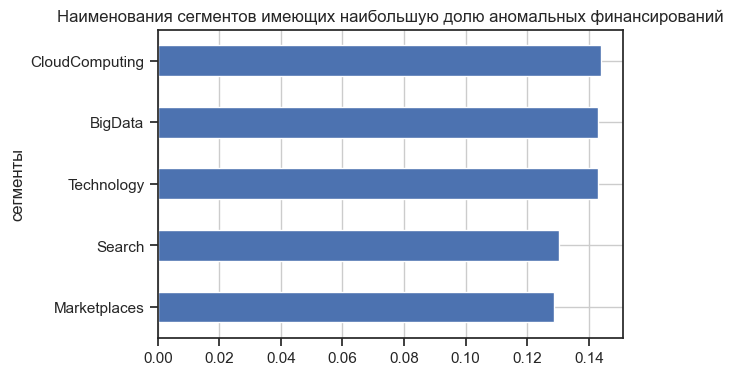

,total_comp,anom_comp,share
market,,,
CloudComputing,146,21,0.1438
Technology,259,37,0.1429
BigData,154,22,0.1429
Search,299,39,0.1304
Marketplaces,210,27,0.1286


In [259]:
data = df.groupby('market').agg(
    total_comp = ('is_anomaly','count'),
    anom_comp = ('is_anomaly', 'sum')
)

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
data['share'] = data['anom_comp'] / data['total_comp']

data = data.sort_values(by='share',ascending=True).tail(5)

plt.figure(figsize=(6,4))

data['share'].plot(
    kind = 'barh',
    title = 'Наименования сегментов имеющих наибольшую долю аномальных финансирований'
)

plt.xlabel('')
plt.ylabel('сегменты')
plt.grid()
plt.show()
display(data.sort_values(by = 'share',ascending=False))

### Вывод по распределению по сегментам (категориям)

По графику видно, что **наибольшую долю** занимает сегмент **«CloudComputing»** — около **0,144** (или **14,4%**).

В топ-5 значений входит сегмент **«Marketplaces»**, который занимает **последнее (пятое) место** с долей около **0,129** (или **12,9%**).

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [260]:
#founded_at
data = df['founded_at']
data = df.loc[df['founded_year'] == 2014, 'founded_at']

print(data.unique().size)
print(data.min())
print(data.max())

# очищаем от аномальных значений
df = df[df['is_anomaly'] == False] 


259
2014-01-01 00:00:00
2014-12-13 00:00:00


### Вывод по полноте данных за 2014 год

Судя по данным, за **2014 год** у нас есть информация о **259 уникальных днях**. Минимальная дата — **1 января**, максимальная — **13 декабря**.

Таким образом, можно предположить, что мы имеем **полные данные за 2014 год**

Также исключили из данных аномальных значений

In [261]:
ss = df.groupby('founded_year')['funding_rounds'].count()
years_keep = ss[ss >= 50].index

df = df[df['founded_year'].isin(years_keep)]

print(df.groupby('founded_year')['funding_rounds'].count().sort_values())

founded_year
1983.0000      50
1984.0000      52
1986.0000      53
1987.0000      55
1985.0000      59
1988.0000      66
1991.0000      69
1990.0000      71
1989.0000      77
1992.0000      94
1993.0000     107
1994.0000     120
1995.0000     184
1996.0000     242
1997.0000     276
1998.0000     339
1999.0000     571
2001.0000     586
2002.0000     614
2000.0000     695
2003.0000     757
2004.0000     881
2005.0000    1106
2014.0000    1459
2006.0000    1472
2007.0000    1981
2008.0000    2072
2009.0000    2680
2010.0000    3515
2013.0000    3977
2011.0000    4650
2012.0000    5063
Name: funding_rounds, dtype: int64


### Фильтрация данных по годам

В данных была сохранена информация только о тех годах, в которых было **более 50 раундов финансирования**.

**Наибольшее количество раундов** было зафиксировано в **2007 году**. Минимальный год, который подходит под условие фильтрации (более 50 раундов), содержит **62 раунда** за год.

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

secondary_market          123386151.0000
product_crowdfunding      132825829.0000
equity_crowdfunding       225199013.0000
convertible_note          449804132.0000
grant                    1088404628.0000
undisclosed              1535847324.0000
angel                    2239639791.0000
post_ipo_equity          2847774699.0000
post_ipo_debt            4185790000.0000
private_equity           4948212965.0000
debt_financing           6739707241.0000
seed                     8376260821.0000
venture                101557110120.0000
dtype: float64


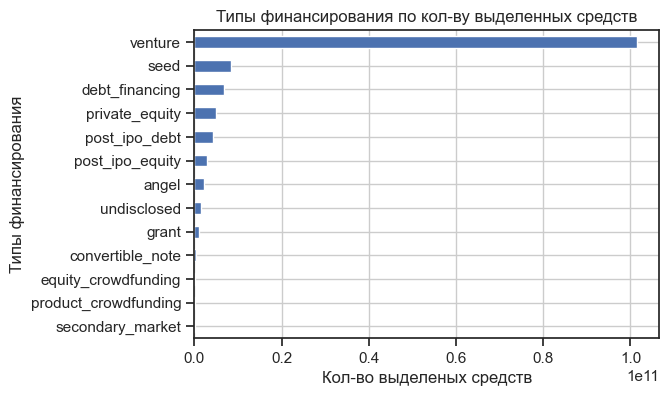

In [262]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

amount = df[funding_types].sum().sort_values(ascending=True)

print(amount)

plt.figure(figsize=(6,4))

amount.plot(
    kind='barh',
    title = 'Типы финансирования по кол-ву выделенных средств',
)

plt.grid()
plt.ylabel('Типы финансирования')
plt.xlabel('Кол-во выделеных средств')
plt.show()

venture                 14083
seed                    11360
angel                    2687
debt_financing           2592
grant                     713
undisclosed               547
private_equity            537
equity_crowdfunding       476
convertible_note          456
product_crowdfunding      164
post_ipo_equity            91
post_ipo_debt              18
secondary_market            7
dtype: int64


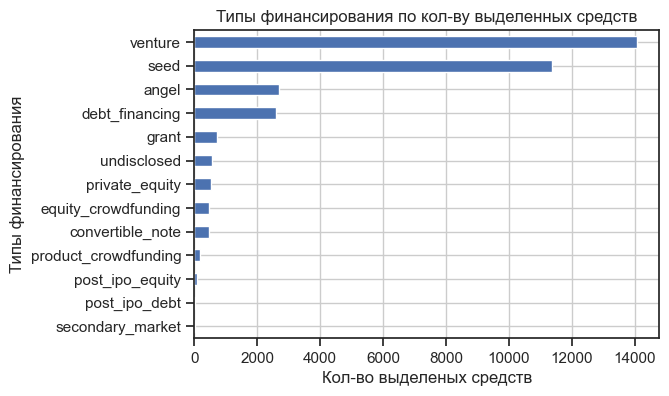

In [263]:

popularity = (df[funding_types] > 0).sum().sort_values(ascending=False)
print(popularity)

plt.figure(figsize=(6,4))

popularity.sort_values(ascending=True).plot(
    kind='barh',
    title = 'Типы финансирования по кол-ву выделенных средств',
)

plt.grid()
plt.ylabel('Типы финансирования')
plt.xlabel('Кол-во выделеных средств')
plt.show()

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [264]:
avg_funding = amount / popularity

avg_funding_sorted = avg_funding.sort_values(ascending=False)

print(avg_funding_sorted)

post_ipo_debt          232543888.8889
post_ipo_equity         31294227.4615
secondary_market        17626593.0000
private_equity           9214549.2831
venture                  7211326.4304
undisclosed              2807764.7605
debt_financing           2600195.6948
grant                    1526514.2048
convertible_note          986412.5702
angel                     833509.4124
product_crowdfunding      809913.5915
seed                      737346.9033
equity_crowdfunding       473107.1702
dtype: float64


### Итоговый вывод по типам финансирования

По графикам и результатам анализа можно сделать следующие выводы:

1. **`venture`** имеет **наибольшую сумму инвестиций**;
2. **`secondary_market`** имеет **наименьшую сумму инвестиций**;
3. **`venture`** имеет **наибольшее количество участий** в инвестициях;
4. **`secondary_market`** имеет **наименьшее количество участий** в инвестициях.

**Соотношение суммы инвестиций и количества участий:**
- **`post_ipo_equity`** — является **наиболее оптимальным** типом финансирования: при относительно небольшом количестве участий привлекается значительная сумма средств;
- **`equity_crowdfunding`** — является **наименее оптимальным**: при большом количестве участий суммарный объём привлечённых средств остаётся низким.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.

